IMPORTANDO BIBLIOTECAS

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

IMPORTANDO DATASET TRATADO

In [2]:
df = pd.read_csv('retail_sales_dataset_tratado.csv', sep=',',header=0)

In [3]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Year,Month,Month Name,Calculated Amount,Amount Difference,Age Group
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,2023,11,November,150,0,25-34
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,2023,2,February,1000,0,25-34
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,2023,1,January,30,0,45-54
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,2023,5,May,500,0,35-44
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,2023,5,May,100,0,25-34


In [5]:
df_limpo = df.copy()

INDICADORES GERAIS

1.1 Quantidade de Transações e Clientes
1.2 Indicadores financeiros
1.3 Indicadores de quantidade
1.4 Indicadores dos clientes
1.5 Criar uma tabela resumida dos indicadores
2 Analise de frequencias
3 Frequencia por genero
4 Frequência por categoria de produto
5 Frequência por faixa etária
6 Frequência por quantidade de itens vendidos
7 Frequencia por preço unitário
8 Frequencia por mes
9 Comparar volume e faturamento por categoria
10 Exportar os resultados das análises para arquivos CSV
11 Conclusões




GRÁFICOS

1. Faturamento por categoria
2. Quantidade de transações por categoria
3. Evolução do faturamento mensal
4. Distribuição dos valores das transações
5. Faturamento por faixa etária
6. Participação por gênero


In [ ]:
# 1.1 Quantidade de transações e clientes únicos

total_transacoes = df_limpo['Transaction ID'].nunique()
total_clientes = df_limpo['Customer ID'].nunique()

print(f'Total de transações: {total_transacoes}')
print(f'Total de clientes: {total_clientes}')

Total de transações: 1000
Total de clientes: 1000


In [11]:
# 1.2 Indicadores financeiros

faturamento_total = df_limpo['Total Amount'].sum()
ticket_medio = df_limpo['Total Amount'].mean()
mediana_transacao = df_limpo['Total Amount'].median()
menor_transacao = df_limpo['Total Amount'].min()
maior_transacao = df_limpo['Total Amount'].max()

print(f'Faturamento total: R${faturamento_total}')
print(f'Ticket médio: R$ {ticket_medio}')
print(f'Mediana das transações: R$ {mediana_transacao}')
print(f'Menor transação: R$ {menor_transacao}')
print(f'Maior transação: R$ {maior_transacao}')

Faturamento total: R$456000
Ticket médio: R$ 456.0
Mediana das transações: R$ 135.0
Menor transação: R$ 25
Maior transação: R$ 2000


In [14]:
# 1.3 Indicadores de quantidade

total_itens = df_limpo['Quantity'].sum()
quantidade_media = df_limpo['Quantity'].mean()
quantidade_mediana = df_limpo['Quantity'].median()

print(f'Total de itens vendidos: {total_itens}')
print(f'Quantidade média de itens por transação: {quantidade_media: .2f}') 
print(f'Quantidade mediana de itens por transação: {quantidade_mediana: .2f}')

Total de itens vendidos: 2514
Quantidade média de itens por transação:  2.51
Quantidade mediana de itens por transação:  3.00


In [15]:
# 1.4 Indicadores dos clientes

idade_media = df_limpo['Age'].mean()
idade_mediana = df_limpo['Age'].median()
idade_minima = df_limpo['Age'].min()
idade_maxima = df_limpo['Age'].max()

print(f'Idade média dos clientes: {idade_media: .2f} anos')
print(f'Idade mediana dos clientes: {idade_mediana} anos')
print(f'Idade mínima dos clientes: {idade_minima} anos')
print(f'Idade máxima dos clientes: {idade_maxima} anos')

Idade média dos clientes:  41.39 anos
Idade mediana dos clientes: 42.0 anos
Idade mínima dos clientes: 18 anos
Idade máxima dos clientes: 64 anos


In [16]:
# 1.5 Criar uma tabela resumida dos indicadores

indicadores = pd.DataFrame({
    "Indicador": [
        "Total de transações",
        "Total de clientes",
        "Faturamento total",
        "Ticket médio",
        "Mediana das transações",
        "Menor transação",
        "Maior transação",
        "Total de itens vendidos",
        "Quantidade média por transação",
        "Idade média",
        "Idade mediana"
    ],
    "Valor": [
        total_transacoes,
        total_clientes,
        faturamento_total,
        ticket_medio,
        mediana_transacao,
        menor_transacao,
        maior_transacao,
        total_itens,
        quantidade_media,
        idade_media,
        idade_mediana
    ]
})

indicadores


,Indicador,Valor
0,Total de transações,1000.000
1,Total de clientes,1000.000
2,Faturamento total,456000.000
3,Ticket médio,456.000
4,Mediana das transações,135.000
5,Menor transação,25.000
6,Maior transação,2000.000
7,Total de itens vendidos,2514.000
8,Quantidade média por transação,2.514
9,Idade média,41.392


In [17]:
indicadores.to_csv(
    "indicadores_gerais_calculados.csv",
    index=False
)


In [18]:
# 2 Analise de frequencias

def tabela_frequencia(dataframe, coluna):
    frequencia = dataframe[coluna].value_counts()
    percentual = (
        dataframe[coluna]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

    tabela = pd.DataFrame({
        "Frequência": frequencia,
        "Percentual (%)": percentual
    })

    return tabela


In [20]:
# 3 Frequencia por genero

frequencia_genero = tabela_frequencia(df_limpo,"Gender")

frequencia_genero


,Frequência,Percentual (%)
Gender,,
Female,510,51.0
Male,490,49.0


In [21]:
faturamento_genero = (
    df_limpo
    .groupby("Gender")["Total Amount"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Transações",
        "sum": "Faturamento",
        "mean": "Ticket médio"
    })
)

faturamento_genero


,Transações,Faturamento,Ticket médio
Gender,,,
Female,510,232840,456.549020
Male,490,223160,455.428571


In [22]:
# 4 Frequência por categoria de produto

frequencia_categoria = tabela_frequencia(df_limpo,"Product Category")

frequencia_categoria


,Frequência,Percentual (%)
Product Category,,
Clothing,351,35.1
Electronics,342,34.2
Beauty,307,30.7


In [25]:
faturamento_categoria = (
    df_limpo.groupby("Product Category")["Total Amount"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Transações",
        "sum": "Faturamento",
        "mean": "Ticket médio"
    })
).sort_values('Faturamento', ascending=False)

faturamento_categoria

,Transações,Faturamento,Ticket médio
Product Category,,,
Electronics,342,156905,458.786550
Clothing,351,155580,443.247863
Beauty,307,143515,467.475570


In [28]:
# 5 Frequência por faixa etária

frequencia_faixa_etaria = tabela_frequencia(df_limpo,"Age Group").sort_values(by='Age Group')

frequencia_faixa_etaria

,Frequência,Percentual (%)
Age Group,,
18-24,149,14.9
25-34,203,20.3
35-44,207,20.7
45-54,225,22.5
55-64,216,21.6


In [29]:
faturamento_faixa_etaria = (
    df_limpo
    .groupby("Age Group", observed=False)["Total Amount"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Transações",
        "sum": "Faturamento",
        "mean": "Ticket médio"
    })
)

faturamento_faixa_etaria


,Transações,Faturamento,Ticket médio
Age Group,,,
18-24,149,74650,501.006711
25-34,203,97090,478.275862
35-44,207,96835,467.801932
45-54,225,97235,432.155556
55-64,216,90190,417.546296


In [32]:
# 6 Frequência por quantidade de itens vendidos

frequencia_quantidade = tabela_frequencia(
    df_limpo,
    "Quantity"
)

frequencia_quantidade



,Frequência,Percentual (%)
Quantity,,
4,263,26.3
1,253,25.3
2,243,24.3
3,241,24.1


In [34]:
faturamento_quantidade = (
    df_limpo
    .groupby("Quantity")["Total Amount"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Transações",
        "sum": "Faturamento",
        "mean": "Ticket médio"
    })
)

faturamento_quantidade

,Transações,Faturamento,Ticket médio
Quantity,,,
1,253,44805,177.094862
2,243,81050,333.539095
3,241,144285,598.692946
4,263,185860,706.692015


In [35]:
# 7 Frequencia por preço unitário

frequencia_preco = tabela_frequencia(
    df_limpo,
    "Price per Unit"
)

frequencia_preco


,Frequência,Percentual (%)
Price per Unit,,
50,211,21.1
25,210,21.0
500,199,19.9
300,197,19.7
30,183,18.3


In [36]:
faturamento_preco = (
    df_limpo
    .groupby("Price per Unit")["Total Amount"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Transações",
        "sum": "Faturamento",
        "mean": "Ticket médio"
    })
    .sort_values("Faturamento", ascending=False)
)

faturamento_preco


,Transações,Faturamento,Ticket médio
Price per Unit,,,
500,199,247500,1243.718593
300,197,155400,788.832487
50,211,26700,126.540284
30,183,13350,72.950820
25,210,13050,62.142857


In [37]:
# 8 Frequencia por mes

frequencia_mes = tabela_frequencia(
    df_limpo,
    "Month"
)

frequencia_mes

,Frequência,Percentual (%)
Month,,
5,105,10.5
10,96,9.6
8,94,9.4
12,91,9.1
4,86,8.6
2,85,8.5
11,78,7.8
1,78,7.8
6,77,7.7


In [38]:
faturamento_mensal = (
    df_limpo
    .groupby(["Year", "Month"])["Total Amount"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Transações",
        "sum": "Faturamento",
        "mean": "Ticket médio"
    })
    .sort_index()
)

faturamento_mensal


Transações  Faturamento  Ticket médio
Year Month                                       
2023 1              76        35450    466.447368
     2              85        44060    518.352941
     3              73        28990    397.123288
     4              86        33870    393.837209
     5             105        53150    506.190476
     6              77        36715    476.818182
     7              72        35465    492.569444
     8              94        36960    393.191489
     9              65        23620    363.384615
     10             96        46580    485.208333
     11             78        34920    447.692308
     12             91        44690    491.098901
2024 1               2         1530    765.000000

In [39]:
# 9 Comparar volume e faturamento por categoria

analise_categoria = (
    df_limpo
    .groupby("Product Category")
    .agg(
        transacoes=("Transaction ID", "nunique"),
        itens_vendidos=("Quantity", "sum"),
        faturamento=("Total Amount", "sum"),
        ticket_medio=("Total Amount", "mean")
    )
    .sort_values("faturamento", ascending=False)
)

analise_categoria


,transacoes,itens_vendidos,faturamento,ticket_medio
Product Category,,,,
Electronics,342,849,156905,458.786550
Clothing,351,894,155580,443.247863
Beauty,307,771,143515,467.475570


In [40]:
# 10 Exportar os resultados das análises para arquivos CSV

frequencia_genero.to_csv(
    "frequencia_genero.csv"
)

frequencia_categoria.to_csv(
    "frequencia_categoria.csv"
)

frequencia_faixa_etaria.to_csv(
    "frequencia_faixa_etaria.csv"
)

frequencia_quantidade.to_csv(
    "frequencia_quantidade.csv"
)

frequencia_preco.to_csv(
    "frequencia_preco_unitario.csv"
)

frequencia_mes.to_csv(
    "frequencia_mes.csv"
)


11 Conclusões

O faturamento total foi de R$ 456.000,00.

Qual foi o ticket médio?
O ticket médio foi de R$ 456,00 por transação.

A mediana foi muito diferente da média?
Sim. A mediana foi de R$ 135,00, enquanto a média foi de R$ 456,00. Essa diferença indica que algumas transações de valores elevados influenciaram significativamente o ticket médio. Por isso, a mediana representa melhor o valor típico de uma transação neste dataset.

Qual categoria teve mais transações?
A categoria Clothing teve mais transações, com 351 vendas, representando 35,1% do total.

Qual categoria teve maior faturamento?
A categoria Electronics teve o maior faturamento, com R$ 156.905,00.

Qual gênero teve maior participação?
O gênero Female teve a maior participação, com 510 transações, representando 51% do total. O gênero Male teve 490 transações, representando 49%.

Qual faixa etária teve mais transações?
A faixa etária de 45 a 54 anos teve mais transações, com 225 vendas.

Qual faixa etária teve maior ticket médio?
A faixa etária de 18 a 24 anos teve o maior ticket médio, de aproximadamente R$ 501,01 por transação.

Qual quantidade de itens apareceu mais vezes?
A quantidade de 4 itens por transação apareceu com maior frequência, ocorrendo em 263 transações.

Qual mês teve maior faturamento?
O mês de maio de 2023 teve o maior faturamento, totalizando R$ 53.150,00.

O mês com maior faturamento também teve mais transações?
Sim. Maio de 2023 também teve o maior número de transações, com 105 vendas.



GRÁFICOS

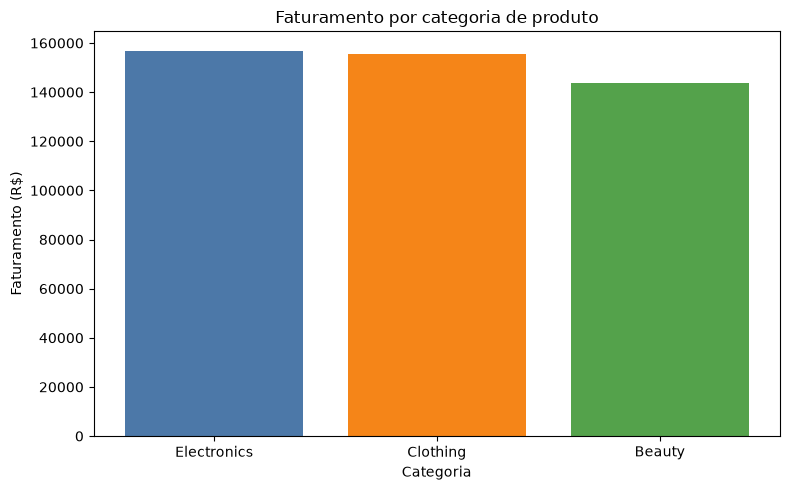

In [47]:
# 1. Faturamento por categoria

faturamento_categoria = (
    df_limpo.groupby("Product Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

plt.bar(
    faturamento_categoria.index,
    faturamento_categoria.values,
    color=["#4C78A8", "#F58518", "#54A24B"]
)

plt.title("Faturamento por categoria de produto")
plt.xlabel("Categoria")
plt.ylabel("Faturamento (R$)")

plt.tight_layout()
plt.show()


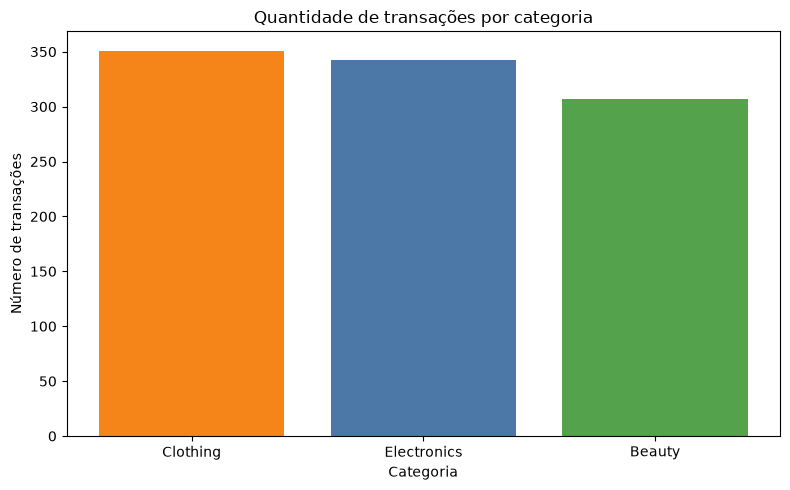

In [ ]:
# 2. Quantidade de transações por categoria

transacoes_categoria = (
    df_limpo["Product Category"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

plt.bar(
    transacoes_categoria.index,
    transacoes_categoria.values,
    color=["#F58518", "#4C78A8", "#54A24B"]
)

plt.title("Quantidade de transações por categoria")
plt.xlabel("Categoria")
plt.ylabel("Número de transações")

plt.tight_layout()
plt.show()


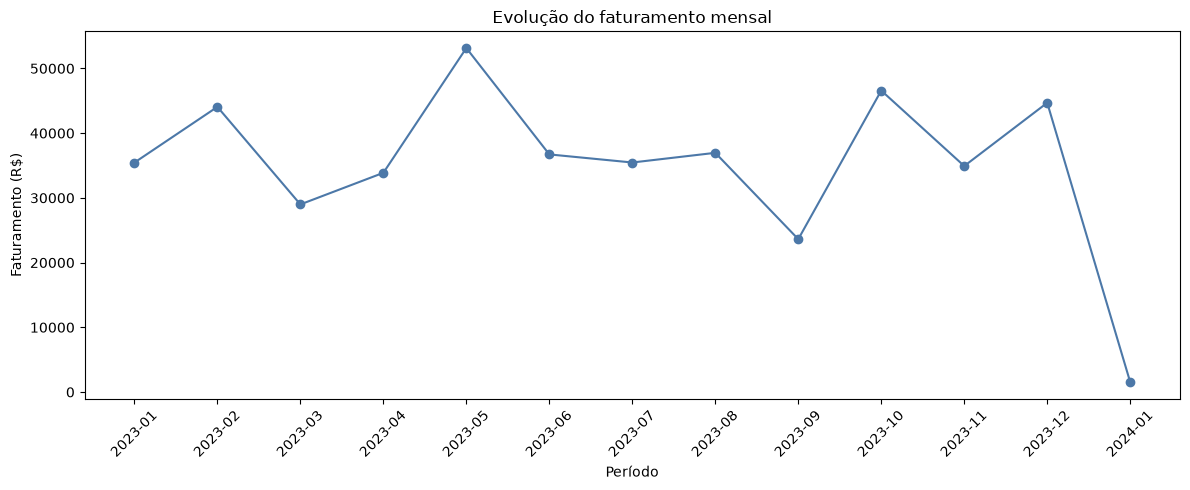

In [ ]:
# 3. Evolução do faturamento mensal

faturamento_mensal = (
    df_limpo.groupby(["Year", "Month"])["Total Amount"]
    .sum()
    .reset_index()
)

faturamento_mensal["Período"] = (
    faturamento_mensal["Year"].astype(str)
    + "-"
    + faturamento_mensal["Month"].astype(str).str.zfill(2)
)

plt.figure(figsize=(12, 5))

plt.plot(
    faturamento_mensal["Período"],
    faturamento_mensal["Total Amount"],
    marker="o",
    color="#4C78A8"
)

plt.title("Evolução do faturamento mensal")
plt.xlabel("Período")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


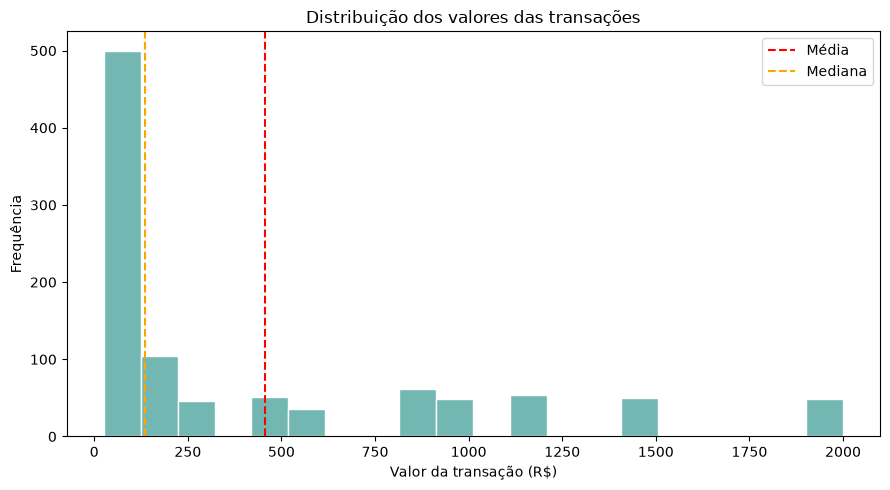

In [ ]:
# 4. Distribuição dos valores das transações

plt.figure(figsize=(9, 5))

plt.hist(
    df_limpo["Total Amount"],
    bins=20,
    color="#72B7B2",
    edgecolor="white"
)

plt.axvline(
    df_limpo["Total Amount"].mean(),
    color="red",
    linestyle="--",
    label="Média"
)

plt.axvline(
    df_limpo["Total Amount"].median(),
    color="orange",
    linestyle="--",
    label="Mediana"
)

plt.title("Distribuição dos valores das transações")
plt.xlabel("Valor da transação (R$)")
plt.ylabel("Frequência")
plt.legend()

plt.tight_layout()
plt.show()


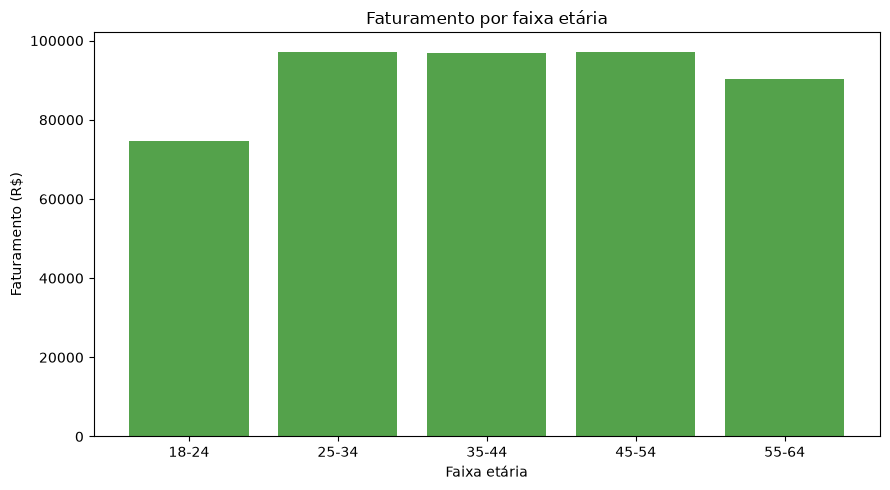

In [48]:
# 5. Faturamento por faixa etária


faturamento_faixa_etaria = (
    df_limpo.groupby("Age Group", observed=False)["Total Amount"]
    .sum()
)

plt.figure(figsize=(9, 5))

plt.bar(
    faturamento_faixa_etaria.index.astype(str),
    faturamento_faixa_etaria.values,
    color="#54A24B"
)

plt.title("Faturamento por faixa etária")
plt.xlabel("Faixa etária")
plt.ylabel("Faturamento (R$)")

plt.tight_layout()
plt.show()


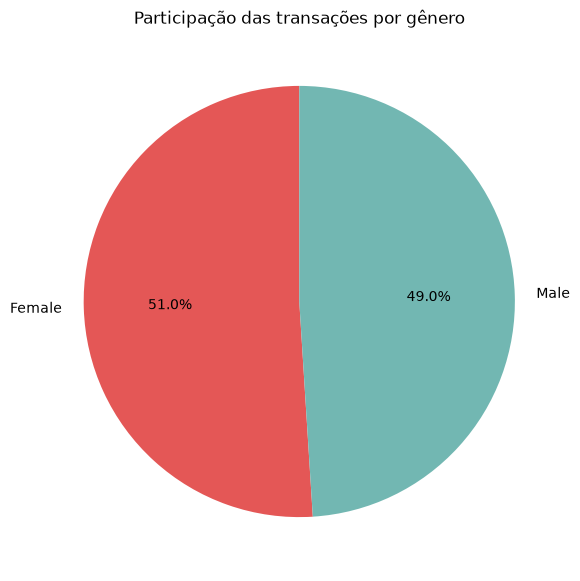

In [ ]:
# 6. Participação por gênero

transacoes_genero = df_limpo["Gender"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    transacoes_genero.values,
    labels=transacoes_genero.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#E45756", "#72B7B2"]
)

plt.title("Participação das transações por gênero")
plt.show()
